# Unsupervised Learning: More Centroid Clustering

In [2]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
import seaborn as sns

/var/folders/9x/0_zzjfd92cnbn1tvtzlg23340000gn/T/ipykernel_16321/1535732297.py:2: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


For today's small group we'll be diving into centroid clustering algorithms in more depth!

First, we need to generate some data to play with:

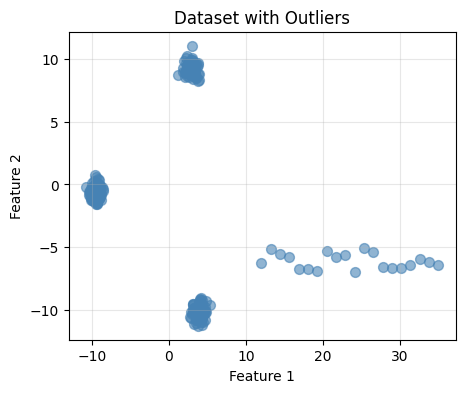

In [4]:
X_base, y_true = make_blobs(n_samples=300, centers=3, n_features=2, 
                            cluster_std=0.8, random_state=42)

X_base[y_true == 0] = X_base[y_true == 0] * 0.6 + [-8, -6] 
X_base[y_true == 1] = X_base[y_true == 1] * 0.6 + [0, 8]    
X_base[y_true == 2] = X_base[y_true == 2] * 0.6 + [8, -6]   

np.random.seed(42)
outlier_x = np.linspace(12, 35, 20)  # Long horizontal spread
outlier_y = np.random.uniform(-7, -5, 20)  # Some vertical spread
outliers = np.column_stack([outlier_x, outlier_y])

X = np.vstack([X_base, outliers])

plt.figure(figsize=(5, 4))
# Plot all data in one color to simulate unsupervised learning
plt.scatter(X[:, 0], X[:, 1], c='steelblue', alpha=0.6, s=50)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Dataset with Outliers')

plt.grid(True, alpha=0.3)
plt.show()

Notice the outliers? Let's see how these affect our centroid clustering algorithms!

----

## Part 1: Implementing K-Means Clustering

### Q: Use sklearn's `KMeans` to cluster the data

In [6]:
# Important: Set random_state = 42 so we all get the same results
# Create a KMeans object 
kmeans = KMeans(n_clusters=3, random_state=42)

# Fit the model to the data (delete line below for student version)
kmeans.fit(X)

# Get the cluster labels
kmeans_labels = kmeans.labels_

# Get the cluster centers
kmeans_centers = kmeans.cluster_centers_

print("K-Means Clustering Complete!")
print(f"Cluster centers shape: {kmeans_centers.shape}")
print(f"Unique labels: {np.unique(kmeans_labels)}")
print(f"\nCluster Centers:\n{kmeans_centers}")

K-Means Clustering Complete!
Cluster centers shape: (3, 2)
Unique labels: [0 1 2]

Cluster Centers:
[[ 2.83539508  9.20186561]
 [-9.5650554  -0.57737217]
 [ 7.1418219  -9.49570386]]


### Visualize K-Means Results

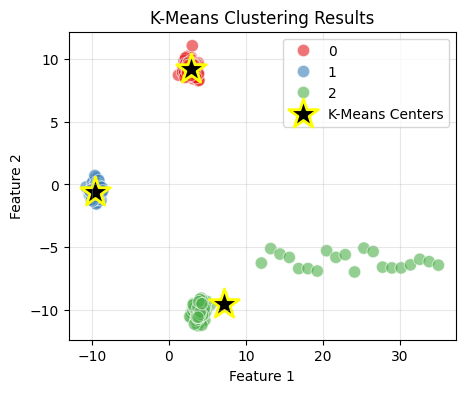

In [7]:
plt.figure(figsize=(5, 4))
# Scatter plot colored by cluster labels
sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=kmeans_labels, 
               palette='Set1', s=80, alpha=0.6)
# Plot cluster centers
plt.scatter(kmeans_centers[:, 0], kmeans_centers[:, 1], 
           c='black', marker='*', s=500, edgecolors='yellow', 
           linewidths=2, label='K-Means Centers')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('K-Means Clustering Results')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Q: How did K-Means perform? Did the outliers affect the cluster centers?


### A:
K-Means uses the mean to calculate the center of each cluster. Since the mean is sensitive to extreme values, outliers can pull cluster centers away from the majority of data points, potentially distorting the clusters and affecting how data points are grouped.

### Q: How could we evaluate the performance quantitatively?

### A:
Measure how spread out the data points are using variance or standard deviation. Calculate the distance between the data point and their cluster center (where lower values indicate more compact values). The distances between various clusters can also be measured to show whether clusters are more separated or close together. 


Use the silhouette score to measure how well data points fit within their assigned clusters compared to other clusters, with higher scores indicating more cohesive and better-separated clusters. The Rand Index can also be used to measure how accurately the clustering groups pairs of data points together or separately compared to their actual known labels, with higher scores indicating better agreement.

----

## Part 2: Implementing K-Medians Clustering

The median of a cluster is calculated by collecting all points assigned to a cluster and then for each dimension separately sorting all values in that dimension and picking the middle value (median). The point with median value for each dimension is then used as the centeroid.

**The goal is to minimize the sum of absolute differences between data points and their assigned centeroid.**

### Q: Fill in the missing code from the K-Medians function

In [ ]:
def KMedians(X, n_clusters=3, max_iters=100, random_state=None):
    """
    Implement K-Medians clustering algorithm.
    """
    if random_state is not None:
        np.random.seed(random_state)
    
    n_samples, n_features = X.shape
    
    # Initialize centers randomly by selecting n_clusters random points from X
    random_indices = np.random.choice(n_samples, n_clusters, replace=False)
    centers = X[random_indices].copy()
    
    for iteration in range(max_iters):
        # Assign each point to the nearest center
        labels = np.zeros(n_samples, dtype=int)
        
        for i in range(n_samples):
            # Calculate distance from point i to each center
            distances = np.array([ np.sum(np.abs(X[i] - center)) for center in centers]) # ANSWER HERE
            # Assign label as the index of the closest center
            labels[i] = np.argmin(distances)
        
        # Store old centers to check for convergence
        old_centers = centers.copy()
        
        # Update centers to be the median of points in each cluster
        for k in range(n_clusters):
            # Get all points assigned to cluster k 
            # ANSWER HERE
            cluster_points = X[labels == k]

            if len(cluster_points) > 0:
                # Calculate median for each dimension
                #ANSWER HERE
                centers[k] = np.median(cluster_points, axis=0)
        
        # Check for convergence
        if np.allclose(old_centers, centers):
            print(f"Converged after {iteration + 1} iterations")
            break
    
    return labels, centers

### Apply K-Medians to the Dataset

In [12]:
# Important: Set random_state = 57 so we all get the same results
# Apply K-Medians function
kmedians_labels, kmedians_centers = KMedians(X, n_clusters=3, max_iters=100, random_state=57)

print("K-Medians Clustering Complete!")
print(f"Cluster centers shape: {kmedians_centers.shape}")
print(f"Unique labels: {np.unique(kmedians_labels)}")
print(f"\nCluster Centers:\n{kmedians_centers}")

Converged after 2 iterations
K-Medians Clustering Complete!
Cluster centers shape: (3, 2)
Unique labels: [0 1 2]

Cluster Centers:
[[  4.03044162 -10.10032093]
 [ -9.52244765  -0.51340591]
 [  2.82539943   9.18937992]]


### Visualize K-Medians Results

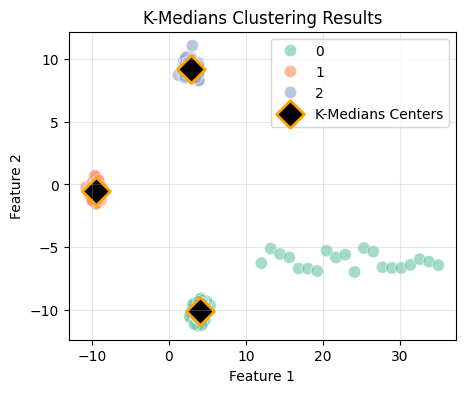

In [13]:
plt.figure(figsize=(5,4))
# Scatter plot colored by cluster labels
sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=kmedians_labels, 
               palette='Set2', s=80, alpha=0.6)
# Plot cluster centers
plt.scatter(kmedians_centers[:, 0], kmedians_centers[:, 1], 
           c='black', marker='D', s=200, edgecolors='orange', 
           linewidths=2, label='K-Medians Centers')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('K-Medians Clustering Results')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Comparing K-Means vs K-Medians


### Side-by-Side Comparison

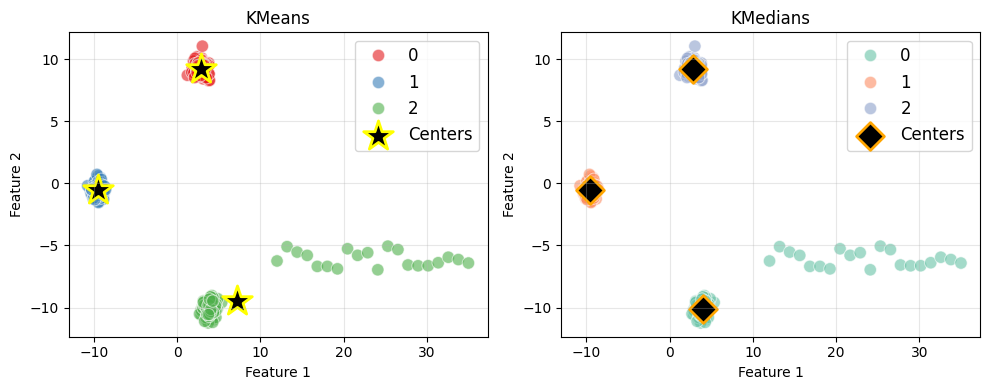

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10,4))

# K-Means plot
sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=kmeans_labels, 
               palette='Set1', s=80, alpha=0.6, ax=axes[0])
axes[0].scatter(kmeans_centers[:, 0], kmeans_centers[:, 1], 
               c='black', marker='*', s=500, edgecolors='yellow', 
               linewidths=2, label='Centers')
axes[0].set_title('KMeans')
axes[0].set_xlabel('Feature 1')
axes[0].set_ylabel('Feature 2')
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=12)

# K-Medians plot
sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=kmedians_labels, 
               palette='Set2', s=80, alpha=0.6, ax=axes[1])
axes[1].scatter(kmedians_centers[:, 0], kmedians_centers[:, 1], 
               c='black', marker='D', s=200, edgecolors='orange', 
               linewidths=2, label='Centers')
axes[1].set_title('KMedians')
axes[1].set_xlabel('Feature 1')
axes[1].set_ylabel('Feature 2')
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=12)

plt.tight_layout()
plt.show()

### Q: Which algorithm performed better on the dataset with outliers? 

Please explain your reasoning!

### A:
K-Medians generally performs better on datasets with outliers because it uses the median rather than the mean to calculate cluster centers. Since the median is less sensitive to extreme values, outliers have less influence on the cluster centers, resulting in more stable and representative clusters.

Imagine we used this process for customer segmentation:

- **K-Means**: Might create a "customer profile" that doesn't represent any real customer (pulled by outliers)
 - **K-Medians**: Creates a profile that represents typical customers in the cluster

### Key Idea 💡
The outliers were assigned to clusters in both cases, but:

- K-Means let them distort the cluster centers
- K-Medians kept the centers true to the main group

### Testing on Normally Distributed Data

Normally distributed data has the same mean, median, and mode

<p align="left">
    <img src = "https://ift.world/wp-content/uploads/2018/06/L1-V1-25_2.jpg" width = "400">
</p>

Let's create some normally distributed clusters to experiment with:

Normal dataset shape: (300, 2)


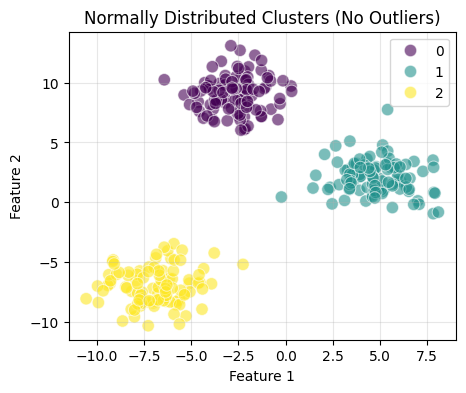

In [16]:
# Create a clean dataset with normally distributed clusters
X_normal, y_normal_true = make_blobs(n_samples=300, centers=3, n_features=2, 
                                     cluster_std=1.5, random_state=42)

print(f"Normal dataset shape: {X_normal.shape}")

# Visualize the dataset
plt.figure(figsize=(5,4))
sns.scatterplot(x=X_normal[:, 0], y=X_normal[:, 1], 
               hue=y_normal_true, palette='viridis', s=80, alpha=0.6)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Normally Distributed Clusters (No Outliers)')
plt.grid(True, alpha=0.3)
plt.show()

### Q: Apply both algorithms to the normally distributed clusters

In [18]:
# Important: Set random_state = 42 for both algorithms
# Apply K-Means
kmeans_normal = KMeans( n_clusters=3, random_state=42)
kmeans_normal.fit( X_normal   )
kmeans_normal_labels = kmeans_normal.labels_
kmeans_normal_centers = kmeans_normal.cluster_centers_

# Apply K-Medians
kmedians_normal_labels, kmedians_normal_centers = KMedians( X_normal, n_clusters=3, max_iters=100, random_state=57 )

print("Clustering on normal data complete!")

Converged after 2 iterations
Clustering on normal data complete!


### Visualize Both Results on Normal Data

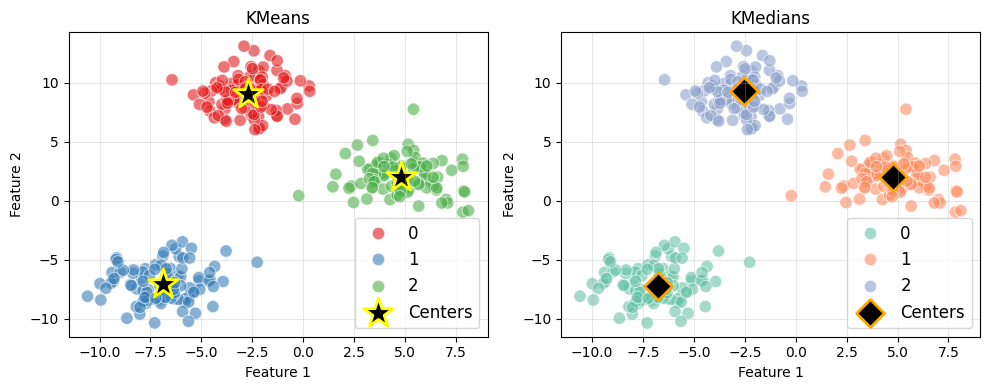

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10,4))

# K-Means plot
sns.scatterplot(x=X_normal[:, 0], y=X_normal[:, 1], hue=kmeans_normal_labels, 
               palette='Set1', s=80, alpha=0.6, ax=axes[0])
axes[0].scatter(kmeans_normal_centers[:, 0], kmeans_normal_centers[:, 1], 
               c='black', marker='*', s=500, edgecolors='yellow', 
               linewidths=2, label='Centers')
axes[0].set_title('KMeans')
axes[0].set_xlabel('Feature 1')
axes[0].set_ylabel('Feature 2')
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=12)

# K-Medians plot
sns.scatterplot(x=X_normal[:, 0], y=X_normal[:, 1], hue=kmedians_normal_labels, 
               palette='Set2', s=80, alpha=0.6, ax=axes[1])
axes[1].scatter(kmedians_normal_centers[:, 0], kmedians_normal_centers[:, 1], 
               c='black', marker='D', s=200, edgecolors='orange', 
               linewidths=2, label='Centers')
axes[1].set_title('KMedians')
axes[1].set_xlabel('Feature 1')
axes[1].set_ylabel('Feature 2')
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=12)

plt.tight_layout()
plt.show()

### Q: How do the performances compare on normally distributed data? Are they similar or different?

### A:
K-Means generally performs better on normally distributed data because the mean accurately represents the center of a symmetric distribution. K-Medians can also perform well, but its results may differ slightly because it uses the median instead. Overall, their performances are often similar when the data has few outliers.

----
## Closing Questions 🧐

### 1. When would you choose K-Means over K-Medians? 
When working with relatively clean, normally distributed data without significant outliers, since the mean provides a good representation of the cluster centers.

### 2. When would you choose K-Medians over K-Means?
When working with datasets containing outliers, since the median is less sensitive to extreme values and produces more stable cluster centers.

### 3. What are the main limitations of both algorithms?
Both require you to specify the number of clusters beforehand, are sensitive to initial center selection, and may struggle with irregularly shaped or overlapping clusters.

### 4. Can you think of a real-world scenario where outliers might significantly impact clustering?
A common example is housing price clustering: A few extremely expensive mansions in a dataset could skew K-Means cluster centers, making typical homes appear less representative of their actual price groups. K-Medians would be less affected by these unusually high prices.